# 1. Data analysis

Validation and pre-analysis of the Fama–French five-factor data (Kenneth R. French Data Library, CRSP vintage 202511; see `docs/DATA.md`).

Features are the five factor returns at month *t*; the target is the market excess return at month *t+1*.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lrd.core.data.loader import FACTOR_COLUMNS, load_fama_french
from lrd.core.data.validation import validate_fama_french

DATA_PATH = "data/raw/F-F_Research_Data_5_Factors_2x3.csv"

## 1.1 Validation

Missing values, garbage values, duplicate or missing months and ordering are errors; extreme values are only flagged (crash months are real data). This check found and led to the removal of a duplicated block of 68 months in the originally committed file.

In [2]:
report = validate_fama_french(DATA_PATH)
print("Status:", "PASSED" if report.ok else "FAILED", report.errors)
print(f"{report.n_monthly_rows} monthly rows, {report.date_range[0]} to {report.date_range[1]}")
report.outliers

Status: PASSED []
749 monthly rows, 1963-07 to 2025-11


,month,column,value,robust_z
0,2000-02,RMW,-0.1895,-12.103178
1,2000-11,RMW,0.1305,8.068785
2,2000-03,RMW,0.1165,7.186262
3,2000-02,SMB,0.1846,6.871702
4,2020-03,HML,-0.1383,-6.027538
5,2002-11,RMW,-0.0925,-5.988551
6,1987-10,Mkt-RF,-0.2319,-5.938053
7,2000-10,RMW,0.0954,5.856173
8,2000-03,SMB,-0.1554,-5.798464
9,2001-02,RMW,0.0912,5.591416


In [3]:
X, y, dates = load_fama_french(DATA_PATH)
frame = pd.DataFrame(X, columns=FACTOR_COLUMNS, index=dates)
frame["target (Mkt-RF t+1)"] = y
stats = pd.DataFrame({"mean": frame.mean(), "std": frame.std(), "skew": frame.skew(),
                      "excess kurtosis": frame.kurt(), "min": frame.min(), "max": frame.max()})
stats.round(4)

,mean,std,skew,excess kurtosis,min,max
Mkt-RF,0.0060,0.0446,-0.5043,1.7355,-0.2319,0.1610
SMB,0.0018,0.0303,0.3637,3.0629,-0.1554,0.1846
HML,0.0028,0.0297,0.1030,2.2051,-0.1383,0.1286
RMW,0.0026,0.0222,-0.3184,11.0751,-0.1895,0.1305
CMA,0.0024,0.0207,0.2694,1.3756,-0.0708,0.0901
target (Mkt-RF t+1),0.0060,0.0446,-0.5046,1.7359,-0.2319,0.1610


## 1.2 Factor returns and volatility regimes

Volatility clusters in regimes — the motivation for local models.

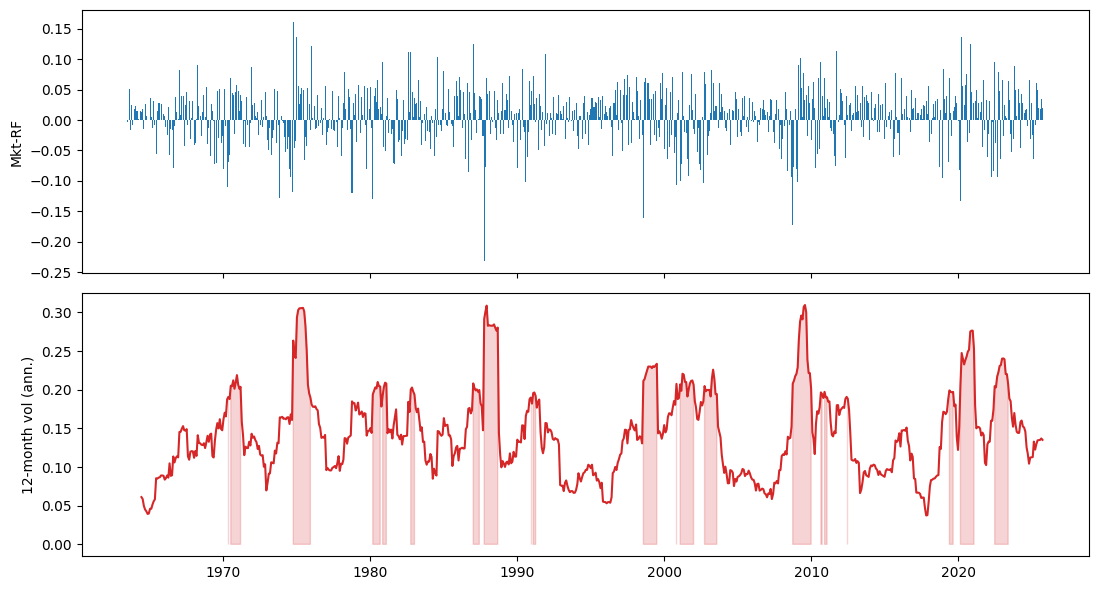

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(dates, frame["Mkt-RF"], width=25)
axes[0].set_ylabel("Mkt-RF")
vol = frame["Mkt-RF"].rolling(12).std() * np.sqrt(12)
axes[1].plot(dates, vol, color="tab:red")
axes[1].fill_between(dates, 0, vol, where=vol > vol.quantile(0.8), color="tab:red", alpha=0.2)
axes[1].set_ylabel("12-month vol (ann.)")
plt.tight_layout()

## 1.3 Distributions and correlations

,Mkt-RF,SMB,HML,RMW,CMA,target (Mkt-RF t+1)
Mkt-RF,1.00,0.28,-0.21,-0.19,-0.35,0.04
SMB,0.28,1.00,0.01,-0.34,-0.08,0.05
HML,-0.21,0.01,1.00,0.09,0.68,-0.07
RMW,-0.19,-0.34,0.09,1.00,0.00,-0.05
CMA,-0.35,-0.08,0.68,0.00,1.00,-0.08
target (Mkt-RF t+1),0.04,0.05,-0.07,-0.05,-0.08,1.00


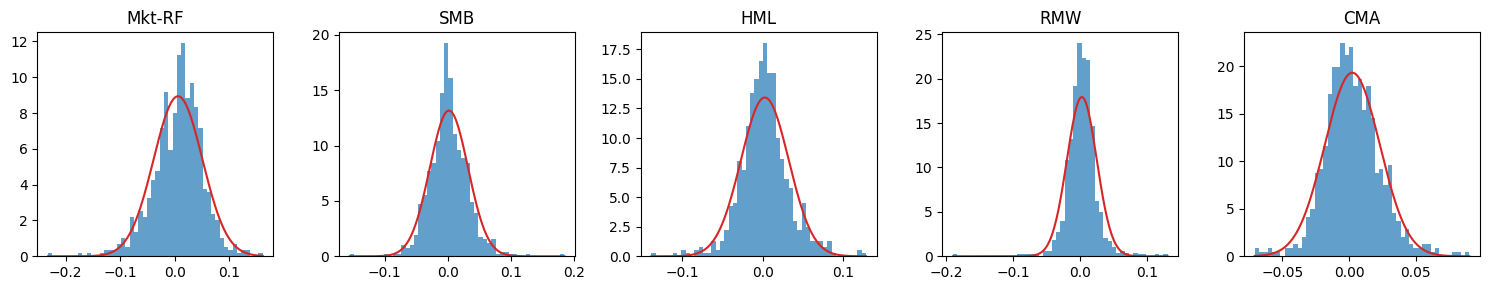

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, col in zip(axes, FACTOR_COLUMNS):
    ax.hist(frame[col], bins=50, density=True, alpha=0.7)
    grid = np.linspace(frame[col].min(), frame[col].max(), 200)
    ax.plot(grid, np.exp(-0.5 * ((grid - frame[col].mean()) / frame[col].std()) ** 2)
            / (frame[col].std() * np.sqrt(2 * np.pi)), color="tab:red")
    ax.set_title(col)
plt.tight_layout()
frame.corr().round(2)

## 1.4 Predictability

How much of next month's return does each factor explain on its own, and how autocorrelated is the target? Both are tiny — which is why no model beats the historical mean by much.

In [6]:
target = frame["target (Mkt-RF t+1)"]
single_factor_r2 = {col: frame[col].corr(target) ** 2 for col in FACTOR_COLUMNS}
acf = {lag: target.autocorr(lag) for lag in range(1, 13)}
print("Single-factor R²:", {k: f"{v:.2%}" for k, v in single_factor_r2.items()})
print("95% noise band for autocorrelation: ±", round(1.96 / np.sqrt(len(target)), 3))
pd.Series(acf, name="autocorrelation").round(3)

Single-factor R²: {'Mkt-RF': '0.18%', 'SMB': '0.21%', 'HML': '0.46%', 'RMW': '0.26%', 'CMA': '0.59%'}
95% noise band for autocorrelation: ± 0.072


1     0.042
2    -0.047
3     0.024
4     0.008
5     0.051
6    -0.047
7     0.021
8    -0.006
9    -0.044
10    0.020
11    0.009
12    0.024
Name: autocorrelation, dtype: float64